# Real Sentinel-1 Volcano Time-Series Imaging

## 1. Problem

Recover the spatially resolved line-of-sight (LOS) deformation history of Fernandina from **288 real interferograms, 98 acquisitions, and the complete 450 x 600 source scene**. These are actual Sentinel-1 A/B descending-track-128 observations, not synthetic images or a few selected pixels. The period 2014-12-13 to 2018-06-19 includes two eruption dates.

A pairwise radar phase difference combines deformation, atmospheric propagation, baseline-dependent elevation error and spatial nuisance structure. Independent spatial unwrapping can additionally leave integer-cycle offsets between coherent regions. The selected method jointly uses the temporal acquisition graph and spatial connected regions, then separates deterministic nuisance contributions from a displacement movie. Five required output quantities are actively reconstructed below.

This notebook reviews a modern numerical port of selected stages of the 2019 MintPy method. It does not claim to rerun every acquisition network, simulated comparison or GNSS validation in that paper. No independent ground-truth displacement movie is available for this bound dataset; reproduced upstream numerical outputs are identified as a **standard-method comparison**, never relabelled truth.

## 2. Data

**Source and identity.** The real processed observation stack is the provider's Fernandina Sentinel-1 descending-track-128 dataset, Zenodo record 3952953, DOI https://doi.org/10.5281/zenodo.3952953, distributed under CC BY 4.0. The complete archive is 750610904 bytes, with verified provider MD5 `089fd092ce705a8aec718d36a2949d5b`. It contains 98 dates and 288 interferograms produced by ISCE/topsStack. Original phase is the second band of a little-endian float32, two-band BIL raster. Coherence is a single float32 band; labels are uint8. The published distributed scene already starts at source row1150/column1070. **No further crop, downsampling, synthetic noise or temporal subsampling is performed here.**

The independently supplied ERA5 LOS product is original float32 data, produced by the provider using a weather model and atmospheric propagation software; it is not inferred from the unknown reconstruction. Its original reference date is 20180619. This review re-references it in space and time before subtraction. The source baseline at a date is the mean of the two supplied swath baseline values relative to 20141213. The acquisition geometry and geolocation are preserved.

**Method source.** The numerical oracle uses MintPy revision `9e0d46b2593483ba89452102efd21c1575662190`, actually verified against the remote repository. The selected paper is Yunjun, Fattahi and Amelung (2019), DOI https://doi.org/10.1016/j.cageo.2019.104331, with archived EarthArXiv postprint version3, DOI https://doi.org/10.31223/osf.io/9sz6m. Source URLs, exact archive hashes, original commands, licenses and private capture index are in `test/validation.md`.

The solver-visible archive `data/raw_data.npz` has SHA256 `00b96aabb032e4e6b06ca062a541d29529c62ca841a3931136ff34720e3ce1fd`. Its arrays contain only observations and legitimate external calibration/correction inputs. Hidden references are loaded separately only after active reconstruction.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| `phase` | `(1, 288, 450, 600)` | float32 | Original unwrapped phase, rad; batch, edge, azimuth, range |
| `coherence` | `(1, 288, 450, 600)` | float32 | Spatial interferometric coherence, dimensionless; same axes |
| `components` | `(1, 288, 450, 600)` | uint8 | Original connected-component labels, dimensionless; zero means unavailable |
| `dates` | `(1, 98)` | int32 | Ordered acquisition dates as YYYYMMDD, calendar dates without a physical unit |
| `pairs` | `(1, 288, 2)` | int16 | Zero-based first/second indices into `dates`, dimensionless |
| `baseline` | `(1, 98)` | float32 | Perpendicular baseline relative to the first acquisition, m; mean of the two supplied swath baseline values |
| `atmospheric_delay` | `(1, 98, 450, 600)` | float32 | Original ERA5-derived LOS displacement contribution, m; subtract after spatial/temporal re-referencing |
| `incidence` | `(1, 450, 600)` | float32 | Original incidence angle, degrees; azimuth, range |
| `latitude` | `(1, 450, 600)` | float64 | Original pixel latitude, degrees north |
| `longitude` | `(1, 450, 600)` | float64 | Original pixel longitude, degrees east |
| `analysis_mask` | `(1, 450, 600)` | bool | All-edge observation-availability mask, dimensionless; 159,762 valid pixels |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Sensor / orbit | Sentinel-1 A/B, descending track 128, VV | dimensionless | Radar platform, viewing track and polarization |
| Acquisition interval | 20141213 to 20180619 | calendar date | All 98 dates retained |
| Interferogram count | 288 | dimensionless | All original temporal edges retained |
| Frame shape | 450 by 600 | pixel | Complete original distributed scene |
| Wavelength | 0.05546576 | m | Phase-to-LOS conversion wavelength |
| Azimuth pixel spacing | 78.08212603857966 | m | Original multilooked sampling |
| Range pixel spacing | 34.94343172072985 | m | Original multilooked slant-range sampling |
| Starting slant range | 799547.2189154713 | m | Column zero range; column $x$ has this value plus $x$ times range spacing |
| Azimuth / range looks | 5 / 15 | dimensionless | Original acquisition processing |
| Heading | -168.01821899414062 | degree | Original satellite heading |
| Reference pixel | row 76, column 156 | zero-based pixel | Original reference point; latitude about -0.30, longitude about -91.43 degrees |
| Original raster subset origin | row 1150, column 1070 | source raster pixel | Original dataset preparation; no further crop is applied here |
| Spatial axes | increasing source azimuth row, increasing slant-range column | dimensionless | Use supplied geolocation for geographic interpretation |
| Temporal gauge | first acquisition | calendar date | Both requested displacement histories start at zero |
| Input ERA5 product reference date | 20180619 | calendar date | Product must be re-referenced to the first acquisition and the reference pixel |
| Eruption dates | 20170910, 20180613 | calendar date | Strict post-event temporal indicators |
| Component availability | zero label means missing; positive labels identify coherent regions | dimensionless | Preserve spatial region boundaries and actual temporal edge availability |
| Spatial connectivity / boundaries | four neighbours; native finite frame, no periodic extension | dimensionless | Connected-region convention |
| Noise information | measured spatial coherence; no calibrated independent phase variance supplied | dimensionless | Reliability varies across pixels and edges |

In [1]:
%matplotlib inline
from pathlib import Path
import sys, time, json, datetime
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
root = Path.cwd()
if not (root / 'data/raw_data.npz').is_file():
    root = root.parent
assert (root / 'data/raw_data.npz').is_file()
sys.path.insert(0, str(root))
from src.preprocessing import load_data, reference_atmosphere
from src.physics_model import network_matrices, closure_integers, dem_design
from src.solvers import reconstruct, unweighted_common_baseline
from src.main import save_submission
from src.visualization import compare_outputs, array_metrics, plot_stages, plot_parameters, plot_traces
print('Actual execution interpreter:', sys.executable)
print('NumPy:', np.__version__)
data = load_data(root/'data/raw_data.npz')
for key, value in data.items():
    print(f'{key:20s} batch-first shape={(1, *value.shape)} dtype={value.dtype}')
print('All-edge-valid pixels:', int(data['analysis_mask'].sum()))

Actual execution interpreter: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe
NumPy: 2.4.6
phase                batch-first shape=(1, 288, 450, 600) dtype=float32
coherence            batch-first shape=(1, 288, 450, 600) dtype=float32
components           batch-first shape=(1, 288, 450, 600) dtype=uint8
dates                batch-first shape=(1, 98) dtype=int32
pairs                batch-first shape=(1, 288, 2) dtype=int16
baseline             batch-first shape=(1, 98) dtype=float32
atmospheric_delay    batch-first shape=(1, 98, 450, 600) dtype=float32
incidence            batch-first shape=(1, 450, 600) dtype=float32
latitude             batch-first shape=(1, 450, 600) dtype=float64
longitude            batch-first shape=(1, 450, 600) dtype=float64
analysis_mask        batch-first shape=(1, 450, 600) dtype=bool
All-edge-valid pixels: 159762


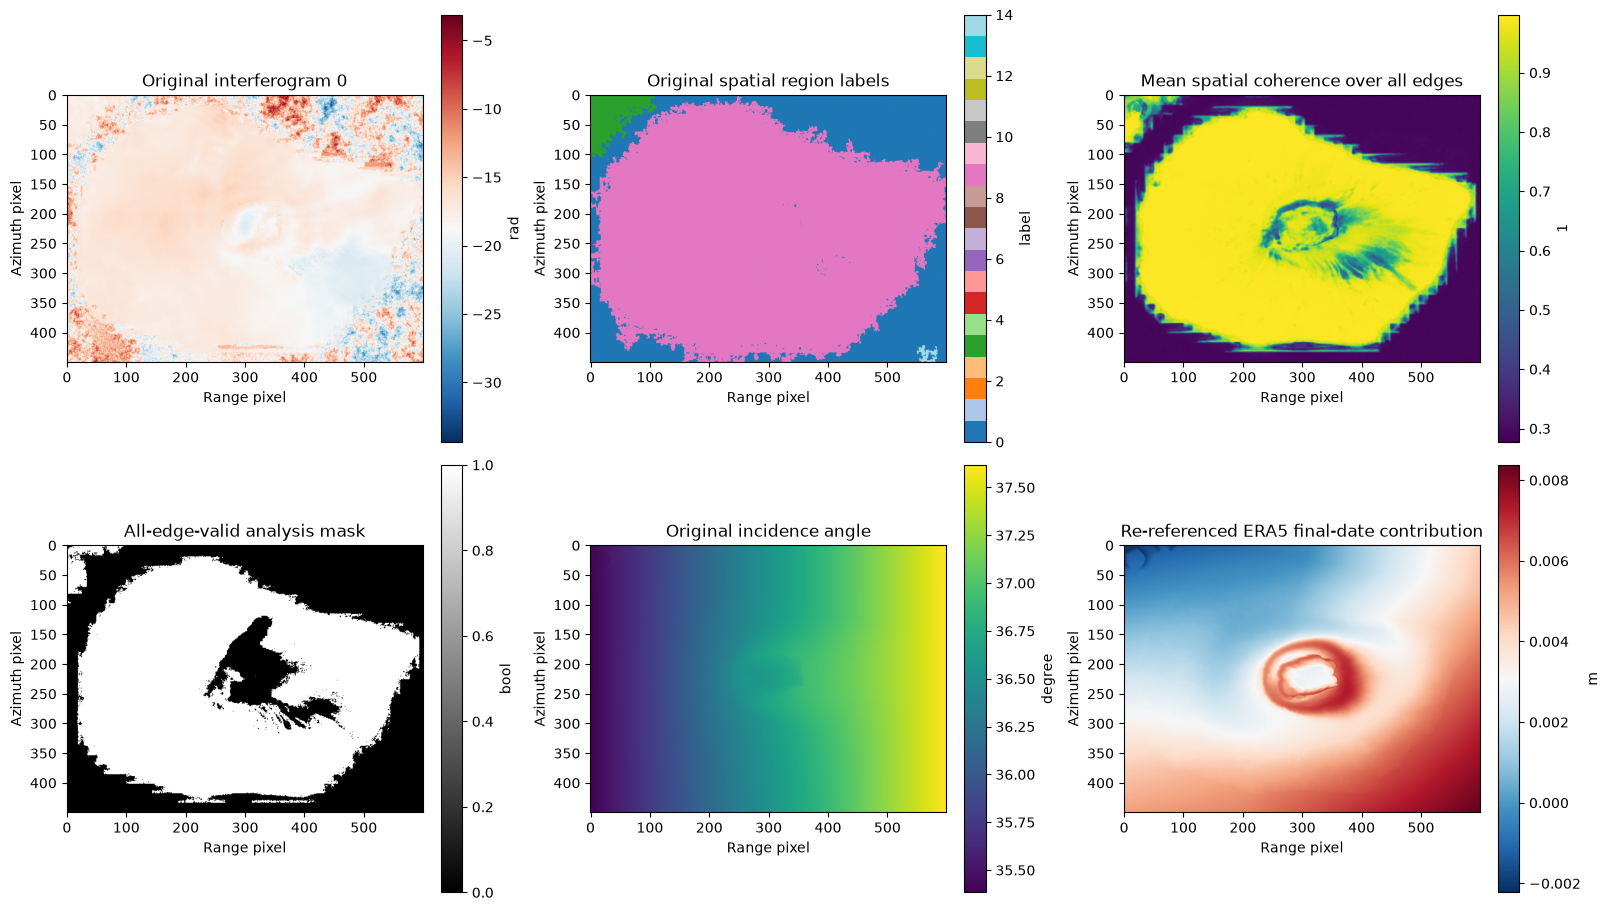

In [2]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9), constrained_layout=True)
weather = reference_atmosphere(data['atmospheric_delay'])
items = [(data['phase'][0], 'Original interferogram 0', 'rad', 'RdBu_r'),
         (data['components'][0], 'Original spatial region labels', 'label', 'tab20'),
         (data['coherence'].mean(axis=0), 'Mean spatial coherence over all edges', '1', 'viridis'),
         (data['analysis_mask'], 'All-edge-valid analysis mask', 'bool', 'gray'),
         (data['incidence'], 'Original incidence angle', 'degree', 'viridis'),
         (weather[-1], 'Re-referenced ERA5 final-date contribution', 'm', 'RdBu_r')]
for ax, (image, title, unit, cmap) in zip(axes.flat, items):
    artist = ax.imshow(image, cmap=cmap)
    ax.set_title(title); ax.set_xlabel('Range pixel'); ax.set_ylabel('Azimuth pixel')
    fig.colorbar(artist, ax=ax, label=unit)
display(fig); plt.close(fig)
del weather

## 3. Physics

For an acquisition $t$ and pixel $p$, the apparent LOS history is

```math
z(t,p)=d(t,p)+a(t,p)+r(t,p)+\frac{b(t)}{\overline R\,\overline{\sin\theta}}h(p).
```

Here $d$ is deformation in metres, $a$ is the external atmospheric contribution in metres, $r$ is an acquisition-dependent affine nuisance field in metres, $b$ is perpendicular baseline in metres, $R$ is slant range in metres, $\theta$ is incidence in degrees before trigonometric conversion, and $h$ is the residual-elevation coefficient in metres. Scene averages use all original geometry pixels. The measured phase on edge $e=(i,j)$ satisfies

```math
\phi(e,p)-\phi(e,p_0)=-\frac{4\pi}{\lambda}[z(j,p)-z(i,p)]
+2\pi k(e,p)+\epsilon(e,p).
```

$\phi$ is unwrapped phase in radians; $p_0=(76,156)$ is the fixed reference pixel; $\lambda=0.05546576$ metres; $k$ is an integer spatial-unwrapping error; and $\epsilon$ is remaining phase/model error. Positive LOS displacement uses $z=-\lambda\psi/(4\pi)$. The first acquisition fixes the temporal gauge.

For each temporal edge, the incidence matrix $A$ has -1 at its first date and +1 at its second, with the first-date column removed. The integrated-velocity operator $B$ instead places consecutive date intervals in the columns crossed by that edge, so $Bv$ is interferometric phase for inter-acquisition velocity $v$ in rad/year. Intervals are computed from float32 day differences divided by365.25. The triangle operator $C$ sums edges $(i,j)+(j,k)-(i,k)$ and therefore satisfies $CA=0$. Departures by whole $2\pi$ cycles diagnose spatial-unwrapping inconsistencies; nonzero subcycle closures also contain real decorrelation and processing noise.

A/B/C/delta shapes: (288, 97) (288, 97) (286, 288) (97, 1)
Temporal graph rank: 97 of 97
Independent cycle identity max |CA|: 0.0
DEM + deformation design: (98, 6) float64


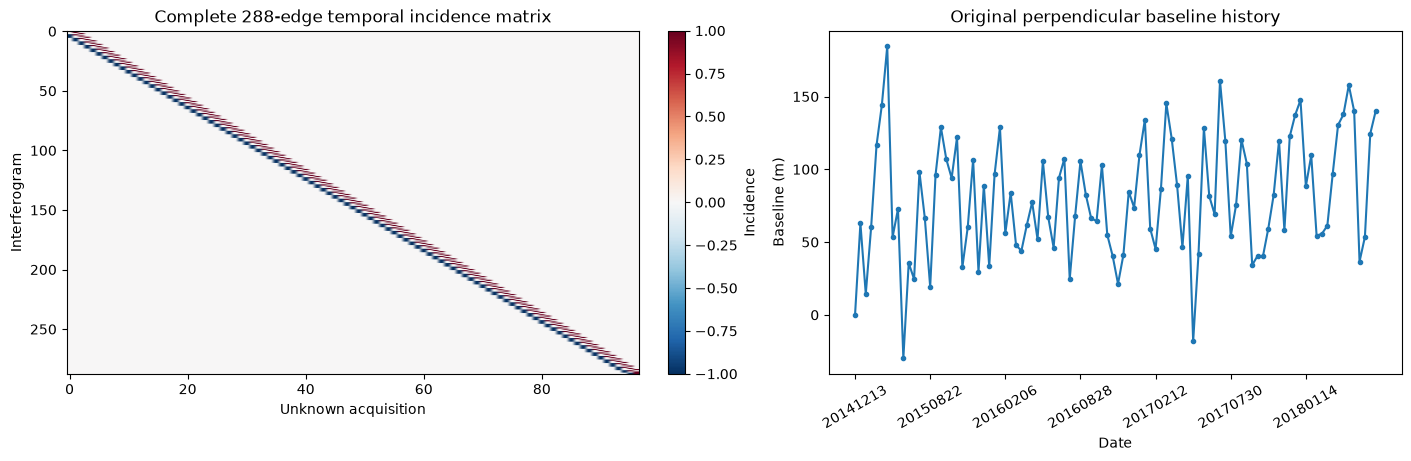

In [3]:
a, b, c, delta = network_matrices(data['dates'], data['pairs'])
print('A/B/C/delta shapes:', a.shape, b.shape, c.shape, delta.shape)
print('Temporal graph rank:', np.linalg.matrix_rank(a), 'of', len(data['dates'])-1)
print('Independent cycle identity max |CA|:', float(np.max(np.abs(c@a))))
assert np.max(np.abs(c@a)) == 0
G = dem_design(data['baseline'], data['incidence'], data['dates'])
print('DEM + deformation design:', G.shape, G.dtype)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
image = axes[0].imshow(a, aspect='auto', cmap='RdBu_r', vmin=-1, vmax=1)
axes[0].set_title('Complete 288-edge temporal incidence matrix'); axes[0].set_xlabel('Unknown acquisition'); axes[0].set_ylabel('Interferogram')
fig.colorbar(image, ax=axes[0], label='Incidence')
axes[1].plot(data['dates'].astype(str), data['baseline'], '.-')
axes[1].set_xticks(np.arange(0,98,14)); axes[1].tick_params(axis='x', rotation=30)
axes[1].set_title('Original perpendicular baseline history'); axes[1].set_ylabel('Baseline (m)'); axes[1].set_xlabel('Date')
display(fig); plt.close(fig)

## 4. Method

**Spatial integer-cycle repair.** The common coherent regions use four-neighbour connectivity. Equal adjacent nonzero labels remain separate. Source area filtering is capped at0.3% of the full frame; the original labelled-image erosion convention is preserved. Two common regions survive, including a disconnected2779-pixel region. For sampled phase $y$, define

```math
q=\operatorname{round}\left[\frac{Cy-\operatorname{wrap}(Cy)}{2\pi}\right],
\quad \widehat u=\arg\min_u\|{-C}u-q\|_2^2+0.01\|u\|_1,
\quad y_{\rm corrected}=y+2\pi\operatorname{round}(\widehat u).
```

Wrap maps into $[-\pi,\pi)$; $q$ contains integer triangle cycles and $u$ contains interferogram-edge corrections. Each common-region correction is the component-wise median over100 rounded sample solutions. The reference region has zero correction. A local connected region receives a correction only when it contains all sample coordinates of a common region, searched in descending area order.

The source uses a generic CVXOPT interior-point solver for this LASSO. The local code solves the **same objective** using explicit ADMM with $D=-C$, penalty $\rho=1$, split variable $w$ and scaled dual $\eta$:

```math
(2D^TD+\rho I)x^{k+1}=2D^Tq+\rho(w^k-\eta^k),\qquad
w^{k+1}=\operatorname{soft}(x^{k+1}+\eta^k,0.01/\rho),\qquad
\eta^{k+1}=\eta^k+x^{k+1}-w^{k+1}.
```

Soft thresholding is $\operatorname{soft}(s,l)=\operatorname{sign}(s)\max(|s|-l,0)$. Initialization is zero. Convergence requires maximum KKT, primal and dual residuals below1e-7; a20000-iteration ceiling raises an error. The numerical backend substitution is disclosed and validated on independent upstream LASSO fixtures and complete spatial propagation; interior-point iterates are not claimed to match ADMM iterates.

**Weighted temporal network.** Missing original component rows are excluded, without deleting acquisition dates. With measured spatial coherence $\gamma$, solve

```math
\widehat v=\arg\min_v\sum_e\max(\gamma_e,0.05)\,[B_ev-y_e]^2,
\quad \psi(t)=\sum_{l<t}\Delta_l\widehat v_l,
\quad z(t)=-\frac{\lambda}{4\pi}\psi(t).
```

The selected published strategy uses *linear coherence weight*, so its square root multiplies both design and observations. Each SVD uses relative cutoff1e-5. Temporal coherence is the magnitude of the mean complex exponential of the **unweighted** phase residual. An independent actively reconstructed comparison uses uniform-weight SBAS on all159762 all-edge-valid pixels.

**Nuisance separation.** Re-reference the independent ERA5 field at the reference pixel and first date, then subtract it. Fit float32 spatial planes $[y,x,1]$ using all-edge-available pixels with temporal coherence at least0.7. The Moore-Penrose inverse uses rcond1e-15; planes are anchored to zero at the reference pixel. This preserves the actual source deramp order and zero-value treatment.

Finally, fit the scene-mean baseline sensitivity jointly with $[1,\tau,\tau^2/2,I(t>T_1),I(t>T_2)]$, where $\tau$ uses `year+(day_of_year-1)/365.25` relative to the first date, and event indicators are strict. The fitted coefficients have units `[m,m/year,m/year²,m,m]`. The joint98-by6 SVD uses cutoff1e-8. Remove only the elevation-residual term; retain the temporal model residual in the final movie. No whole-history model fit is substituted for the reconstructed measurements.

The next cell actively executes **every selected stage on the complete raw observations**. It neither loads an archived reconstruction nor imports MintPy.

### Verified LASSO backend discrepancy

The CVXOPT oracle and local ADMM solve the same convex LASSO objective, but their individual coefficient vectors are not identical. Among 28,800 sampled coefficients, nine rounded values differ, across four sample pixels. The actual difference has Frobenius norm 0.7920480220 and closure-image norm 0.0050718090 (maximum absolute closure difference 0.0003704676); it is not exactly a null-space vector. The local proximal KKT residual is 6.9795e-8 versus 6.0454930e-4 for the original backend. Local objective values are no worse, with maximum local-minus-original objective -7.9200372e-7. Independent active-support null-space perturbations preserve both closure predictions and L1 norm to 1e-12 on each of the four affected samples, proving genuine nonuniqueness; the observed differences also include original stopping precision.

Region-wise median rounded corrections agree for every one of the 288 edges. Full spatially repaired phase agrees bitwise at all 77,760,000 values, and all five complete cleaned output quantities have zero NRMSE against the original method. Validation therefore checks the convex objective/KKT condition and independent nonuniqueness proof at this stage, plus exact scientific region corrections; it does not claim bitwise agreement of the CVXOPT trajectory or individual sample coefficients. The original stricter coefficient test failure and all nine half-integer distances are retained in the private audit indexed by test/validation.md.


In [4]:
start = time.perf_counter()
output, diagnostics = reconstruct(data, workers=4)
reconstruction_seconds = time.perf_counter()-start
save_submission(output, root/'output/reconstruction.npz')
print('Fresh complete reconstruction seconds:', reconstruction_seconds)
print('Actual interpreter:', sys.executable)
print('Surviving regions:', [(r['area'], int(np.count_nonzero(r['ambiguity'])), r['iterations'], r['kkt_residual']) for r in diagnostics['regions']])
print('Spatial-plane fit pixels:', int(diagnostics['fit_mask'].sum()))

Fresh complete reconstruction seconds: 423.731932100025
Actual interpreter: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe
Surviving regions: [(155840, 0, 0, 0.0), (2779, 28, 380, 6.979500516597625e-08)]
Spatial-plane fit pixels: 159447


In [5]:
start = time.perf_counter()
uniform, uniform_quality = unweighted_common_baseline(diagnostics['corrected_phase'], data['analysis_mask'], b, delta)
uniform_seconds = time.perf_counter()-start
print('Fresh uniform-weight SBAS comparison seconds:', uniform_seconds)

Fresh uniform-weight SBAS comparison seconds: 14.499489100067876


## 5. Results

The comparison below distinguishes **this task's reproduced original MintPy outputs** from **fresh local outputs computed above**. No numbers are copied from paper figure captions or cached reports. The hidden standard-method arrays provide a numerical reference, not physical truth. Both quantitative agreement and physical observation consistency are inspected.

Cosine NCC uses flattened arrays without subtracting their mean. NRMSE is RMS error divided by the reference dynamic range. All98dates and all required coefficient maps participate at the fixed public observation-availability mask. No alignment, cropping or fitted scaling is applied. The independent Judge also checks circular phase consistency with the original measurements.

In [6]:
with np.load(root/'evaluation/baseline_reference.npz', allow_pickle=False) as reference_file:
    upstream = {key: reference_file[key][0] for key in reference_file.files}
with np.load(root/'notebooks/reference_outputs/upstream_uniform_sbas.npz', allow_pickle=False) as reference_file:
    upstream_uniform = {key: reference_file[key] for key in reference_file.files}
metrics = compare_outputs(output, upstream, data['analysis_mask'])
print('Quantity                         Fresh/upstream NCC       Dynamic-range NRMSE')
for key, score in metrics.items():
    print(f'{key:32s} {score["ncc"]:.16g} {score["nrmse"]:.16g}')
for i, frame in enumerate(upstream_uniform['frames']):
    # The first acquisition is identically zero: compare exact equality, not undefined NCC.
    fresh = uniform[frame][data['analysis_mask']]
    archived = upstream_uniform['network_maps'][i][data['analysis_mask']]
    print('Uniform baseline frame', int(frame), 'max abs difference (m):', float(np.max(np.abs(fresh-archived))))
import subprocess
result = subprocess.run([sys.executable, str(root/'evaluation/judge.py'), '--prediction', str(root/'output/reconstruction.npz'), '--report', str(root/'output/judge_report.json')], cwd=root, capture_output=True, text=True)
print(result.stdout)
assert result.returncode == 0, result.stderr
judge_report = json.loads((root/'output/judge_report.json').read_text(encoding='utf8'))
assert judge_report['passed']

Quantity                         Fresh/upstream NCC       Dynamic-range NRMSE
reconstruction                   0.9999999999999998 0
dem_error                        1 0
deformation_parameters           1 0
temporal_coherence               1 0
network_timeseries               1 0
Uniform baseline frame 0 max abs difference (m): 0.0
Uniform baseline frame 30 max abs difference (m): 0.0
Uniform baseline frame 60 max abs difference (m): 0.0
Uniform baseline frame 97 max abs difference (m): 0.0
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "reconstruction_ncc": 0.9999999999999998,
    "reconstruction_nrmse": 0.0,
    "dem_error_ncc": 1.0,
    "dem_error_nrmse": 0.0,
    "deformation_parameters_ncc": 1.0000000000000002,
    "deformation_parameters_nrmse": 0.0,
    "temporal_coherence_ncc": 1.0,
    "temporal_coherence_nrmse": 0.0,
    "network_timeseries_ncc": 1.0,
    "network_timeseries_nrmse": 0.0,
    "observation_coherence": 0.994020419696998
  },
  "thresholds": {
    "rec

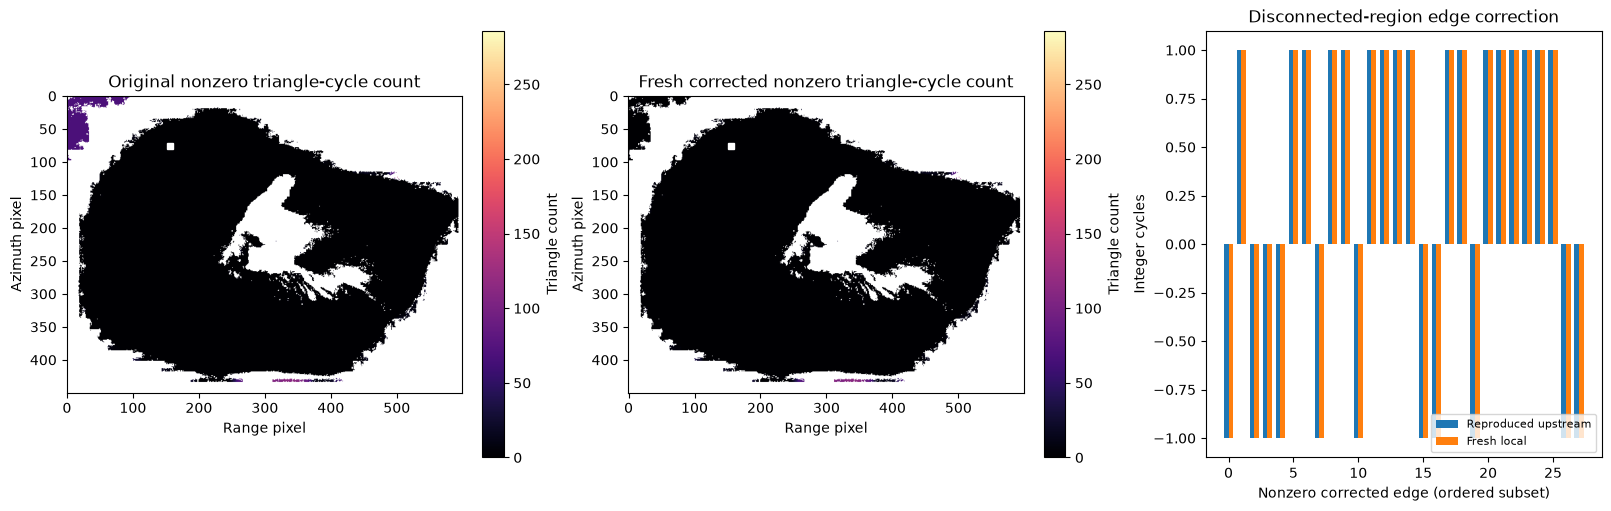

Mean nonzero triangle counts before/after on public mask: [1.715069916500795, 0.39765401034038134]


In [7]:
# Full-frame closure diagnostics are evaluated in memory-bounded blocks.
flat_raw = data['phase'].reshape(288, -1)
flat_corrected = diagnostics['corrected_phase'].reshape(288, -1)
reference_phase = data['phase'][:, 76, 156][:, None]
closure_counts = []
for values, needs_reference in [(flat_raw, True), (flat_corrected, False)]:
    count = np.zeros(450*600, np.int32)
    for first in range(0, count.size, 4096):
        block = values[:, first:first+4096].copy()
        if needs_reference:
            block -= reference_phase
        count[first:first+4096] = np.count_nonzero(closure_integers(c.astype(np.float64), block), axis=0)
    closure_counts.append(count.reshape(450,600))
fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
for ax, image, title in zip(axes[:2], closure_counts, ['Original nonzero triangle-cycle count', 'Fresh corrected nonzero triangle-cycle count']):
    artist = ax.imshow(np.ma.masked_where(~data['analysis_mask'], image), vmin=0, vmax=286, cmap='magma')
    ax.set_title(title); ax.set_xlabel('Range pixel'); ax.set_ylabel('Azimuth pixel')
    ax.plot(156,76,'ws', markersize=5)
    fig.colorbar(artist, ax=ax, label='Triangle count')
with np.load(root/'test/fixtures/upstream_regions.npz', allow_pickle=False) as reference_regions:
    original_offsets = reference_regions['ambiguity_1']
fresh_offsets = diagnostics['regions'][1]['ambiguity']
selected = np.flatnonzero((original_offsets != 0) | (fresh_offsets != 0))
axes[2].bar(np.arange(len(selected))-.18, original_offsets[selected], width=.36, label='Reproduced upstream')
axes[2].bar(np.arange(len(selected))+.18, fresh_offsets[selected], width=.36, label='Fresh local')
axes[2].set_title('Disconnected-region edge correction'); axes[2].set_xlabel('Nonzero corrected edge (ordered subset)'); axes[2].set_ylabel('Integer cycles'); axes[2].legend(fontsize=8)
display(fig); plt.close(fig)
print('Mean nonzero triangle counts before/after on public mask:', [float(x[data['analysis_mask']].mean()) for x in closure_counts])

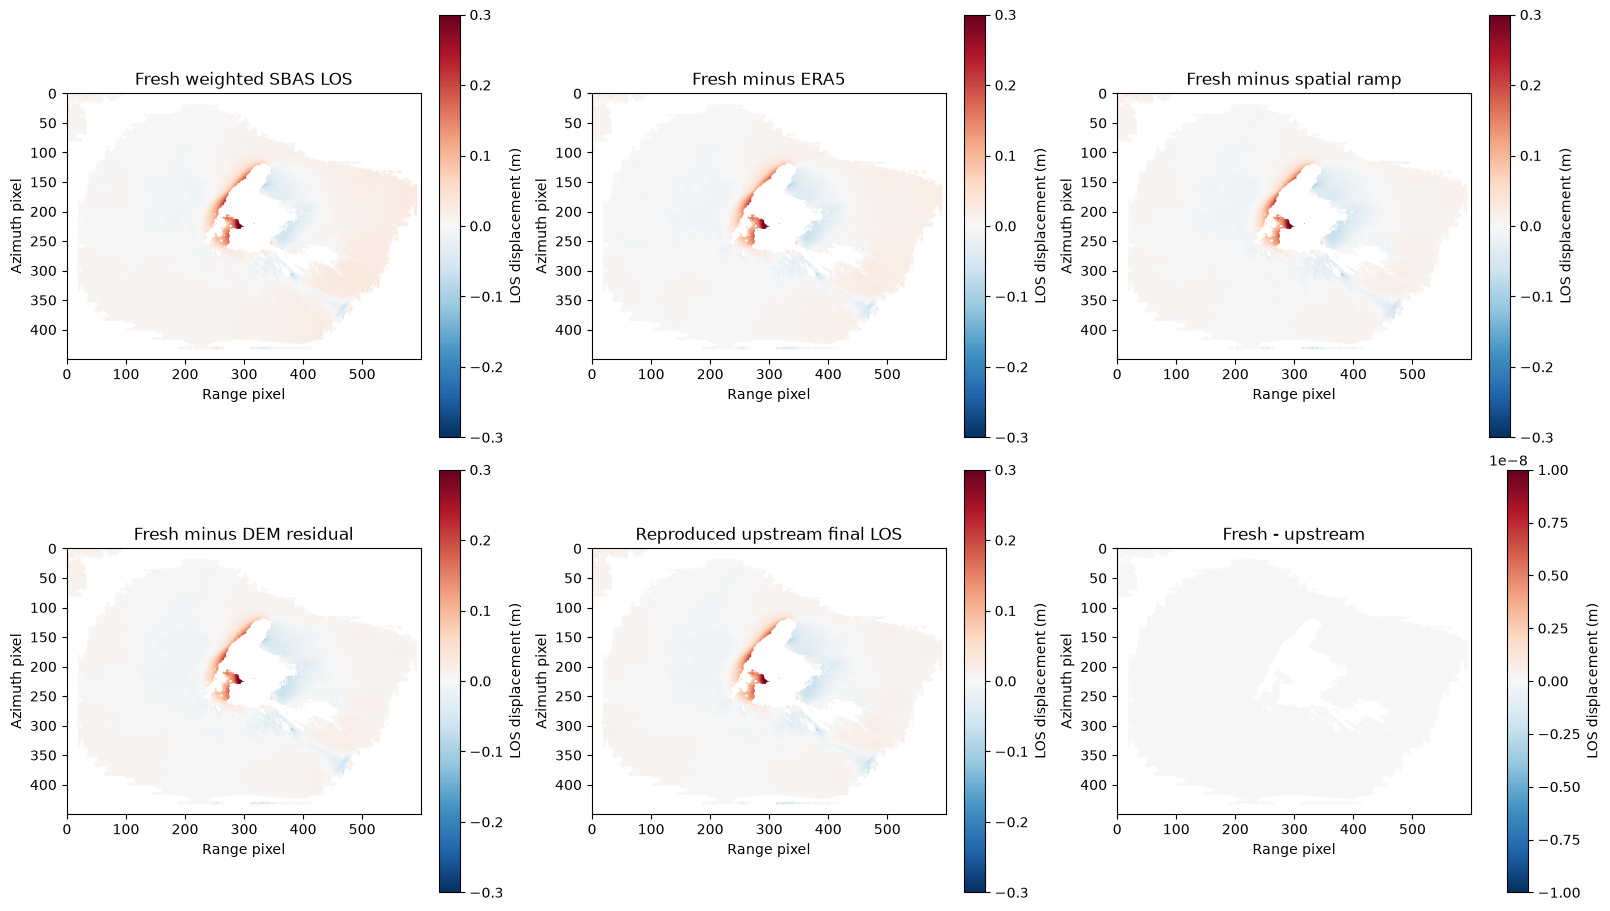

Fresh nuisance-correction RMS over public analysis pixels (m):
ERA5 contribution 0.004481973959354438
Spatial ramp 0.00681684892432122
DEM contribution 0.0007239045243789994
Temporal model residual 0.004376868697515429


In [8]:
fig = plot_stages(data, output, diagnostics, upstream)
display(fig); plt.close(fig)
print('Fresh nuisance-correction RMS over public analysis pixels (m):')
for name, array in [('ERA5 contribution', diagnostics['atmosphere']), ('Spatial ramp', diagnostics['spatial_ramp']), ('DEM contribution', diagnostics['deramped']-output['reconstruction']), ('Temporal model residual', diagnostics['residual'])]:
    print(name, float(np.sqrt(np.mean(np.asarray(array[:, data['analysis_mask']], np.float64)**2))))

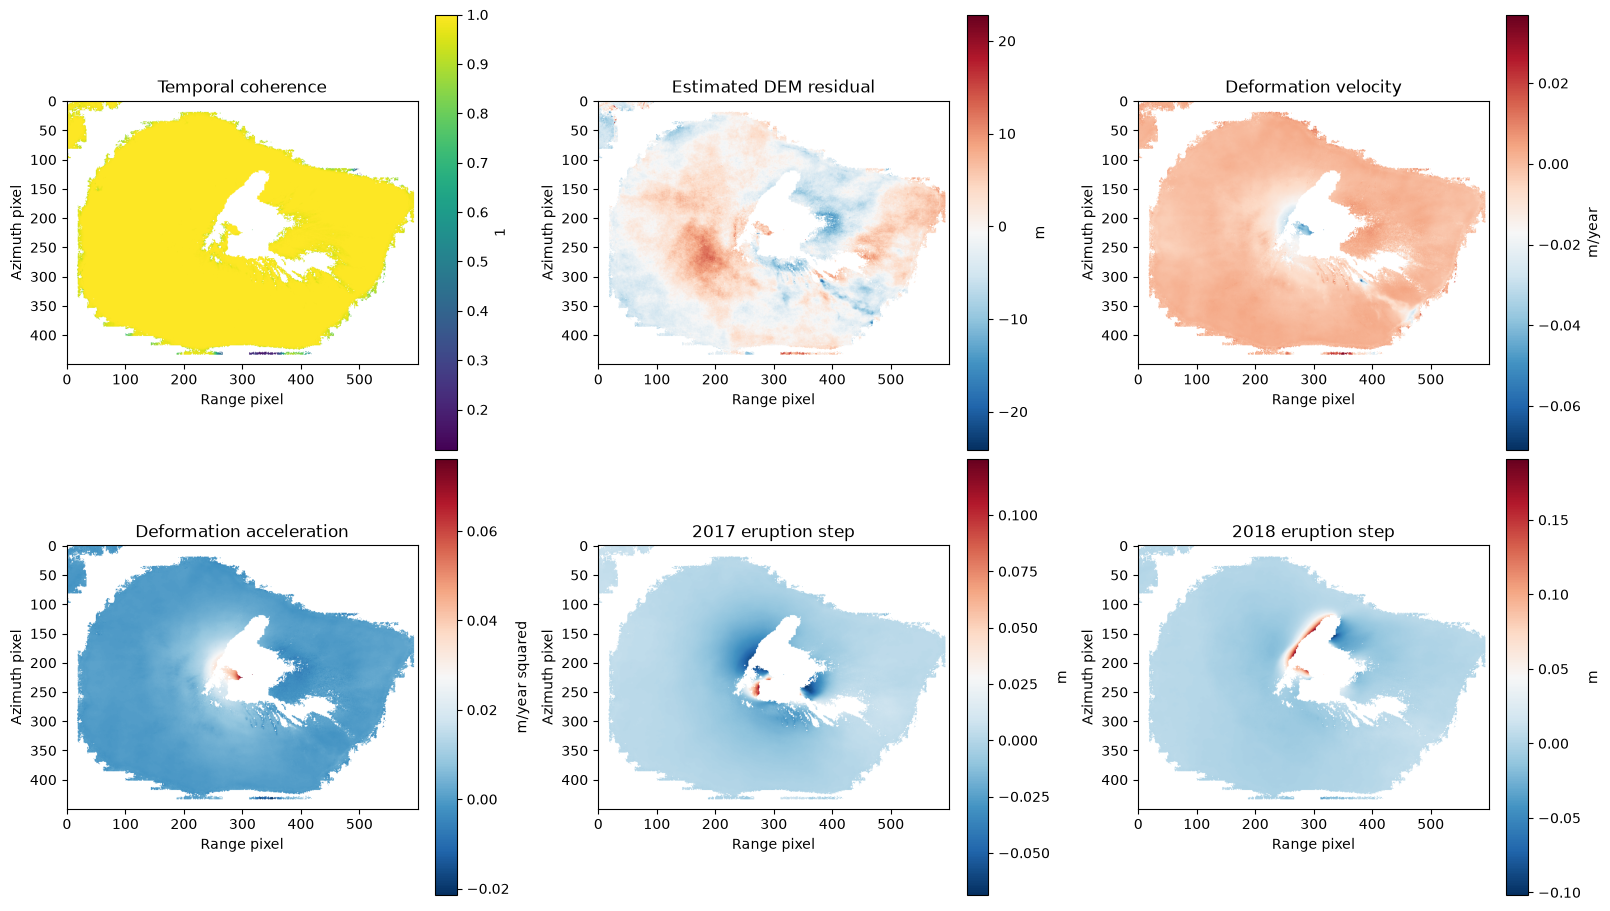

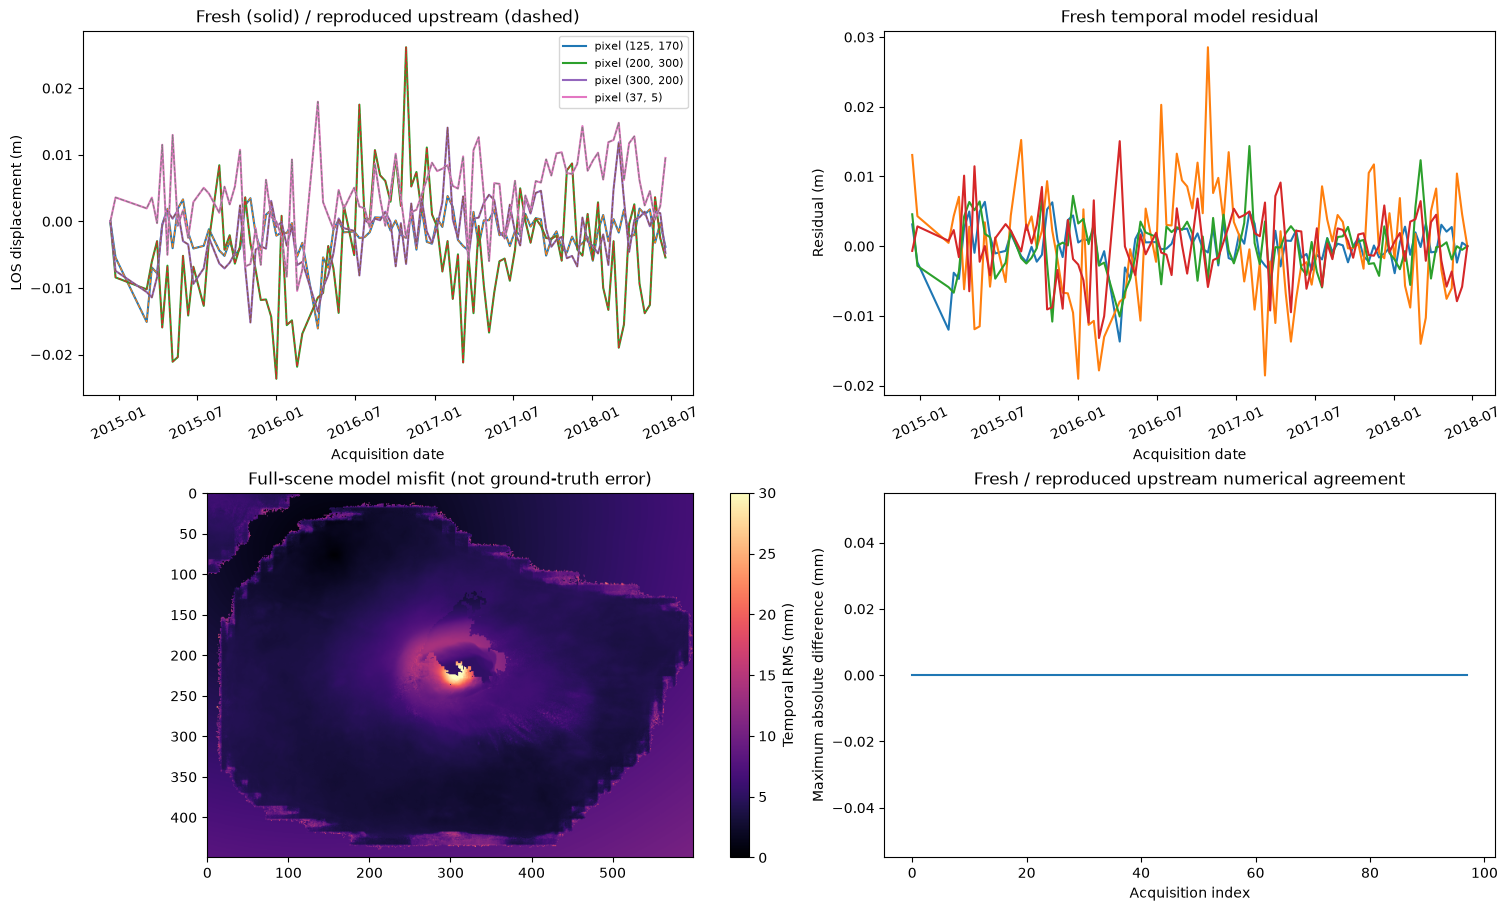

In [9]:
fig = plot_parameters(data, output, diagnostics)
display(fig); plt.close(fig)
calendar = np.array([datetime.datetime.strptime(str(int(x)), '%Y%m%d') for x in data['dates']])
coordinates = [(125,170),(200,300),(300,200),(37,5)]
fig = plot_traces(output, upstream, diagnostics, calendar, coordinates)
display(fig); plt.close(fig)

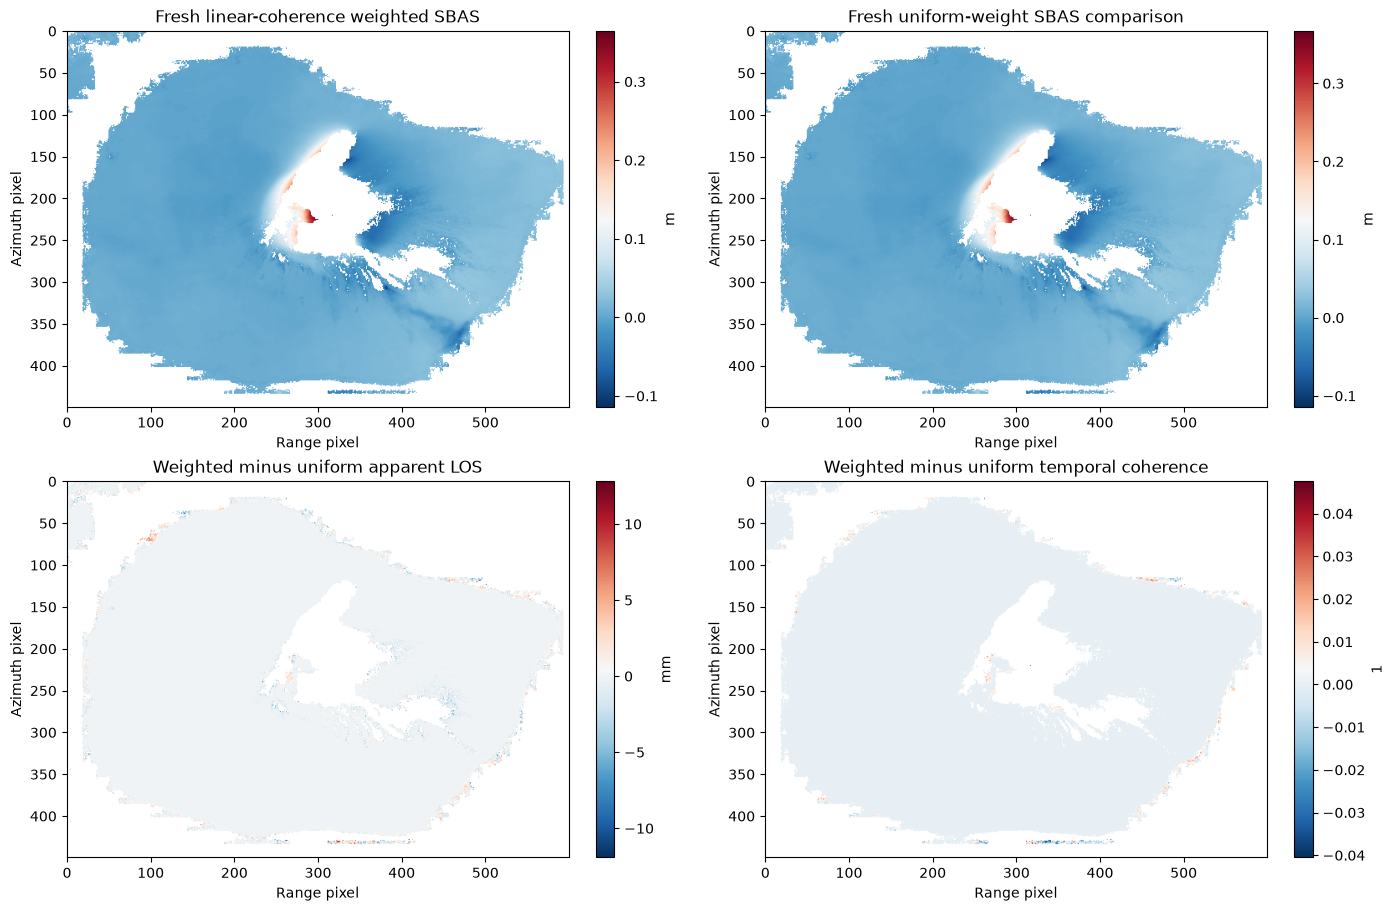

Mean temporal coherence on common observation mask:
Weighted fresh: 0.994020402431488
Uniform fresh: 0.9939572215080261
Weighted-vs-uniform apparent-LOS RMS difference (m): 0.0003745961163351199
Fresh full-method runtime (s): 423.731932100025 ; independent uniform comparison runtime (s): 14.499489100067876


In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)
images = [(output['network_timeseries'][-1], 'Fresh linear-coherence weighted SBAS', 'm', 'RdBu_r'),
          (uniform[-1], 'Fresh uniform-weight SBAS comparison', 'm', 'RdBu_r'),
          ((output['network_timeseries'][-1]-uniform[-1])*1000, 'Weighted minus uniform apparent LOS', 'mm', 'RdBu_r'),
          (output['temporal_coherence']-uniform_quality, 'Weighted minus uniform temporal coherence', '1', 'RdBu_r')]
for ax, (image,title,unit,cmap) in zip(axes.flat,images):
    artist = ax.imshow(np.ma.masked_where(~data['analysis_mask'], image), cmap=cmap)
    ax.set_title(title); ax.set_xlabel('Range pixel'); ax.set_ylabel('Azimuth pixel')
    fig.colorbar(artist, ax=ax, label=unit)
display(fig); plt.close(fig)
print('Mean temporal coherence on common observation mask:')
print('Weighted fresh:', float(output['temporal_coherence'][data['analysis_mask']].mean()))
print('Uniform fresh:', float(uniform_quality[data['analysis_mask']].mean()))
print('Weighted-vs-uniform apparent-LOS RMS difference (m):', float(np.sqrt(np.mean((output['network_timeseries'][:,data['analysis_mask']].astype(np.float64)-uniform[:,data['analysis_mask']])**2))))
print('Fresh full-method runtime (s):', reconstruction_seconds, '; independent uniform comparison runtime (s):', uniform_seconds)

## 6. Conclusion

The active reconstruction preserves the complete98-date network and original spatial frame. It estimates a disconnected-region whole-cycle correction, performs a separate weighted inverse problem at every pixel, subtracts an independently measured weather-model contribution, and jointly separates geometric/elevation and eruption-related temporal structure. The paired upstream/fresh metrics and integer-correction bars test numerical fidelity; the stage maps, event parameter maps, temporal traces and residuals provide the physical review. Uniform-weight SBAS is reconstructed separately to expose the effect of weighting rather than assumed to be identical.

The final movie retains the temporal-model residual and therefore more than a fitted quadratic-plus-step curve. High temporal coherence and agreement with MintPy establish reproducibility and network consistency; they do not establish independent physical accuracy. Important unresolved interpretation limits include single-LOS sensitivity, phase ambiguities that preserve closure, residual atmospheric delay, broad deformation potentially absorbed by spatial deramping, and the2018eruption step having only limited post-event sampling. No GNSS truth, synthetic target or invented paper measurement is used to remove these real-data difficulties.